<a href="https://colab.research.google.com/github/nudratnoor2104/AI_models_comparing/blob/main/AI_model_comparison.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from imblearn.under_sampling import RandomUnderSampler

In [ ]:
from google.colab import files
uploaded = files.upload()
dataset = pd.read_csv("5.csv")
dataset.head()

Saving 5.csv to 5.csv


,Age,Workclass,Final Weight,Education,Education Number of Years,Marital-status,Occupation,Relationship,Race,Sex,Capital-gain,Capital-loss,Hours-per-week,Native-country,target
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


In [ ]:
print("Number of data points:", dataset.shape[0])
print("Number of input features:", dataset.shape[1] - 1)
print("Number of total columns:", dataset.shape[1])
print("\nFeature data types:")
print(dataset.dtypes)

Number of data points: 48842
Number of input features: 14
Number of total columns: 15

Feature data types:
Age                           int64
Workclass                    object
Final Weight                  int64
Education                    object
Education Number of Years     int64
Marital-status               object
Occupation                   object
Relationship                 object
Race                         object
Sex                          object
Capital-gain                  int64
Capital-loss                  int64
Hours-per-week                int64
Native-country               object
target                       object
dtype: object


In [ ]:
dataset.isnull().sum()
for col in dataset.columns:
    count = (dataset[col] == '?').sum()
    if count > 0:
        print(col, count)

Workclass 2799
Occupation 2809
Native-country 857


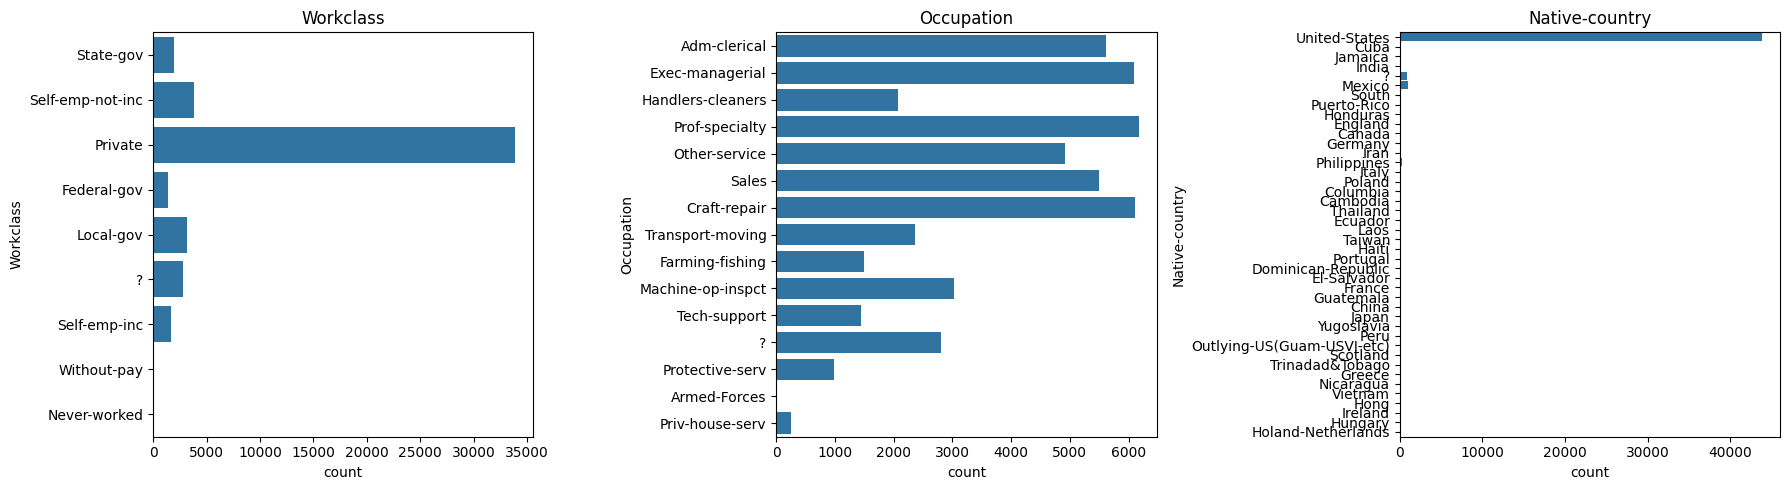

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.countplot(y=dataset['Workclass'], ax=axes[0])
axes[0].set_title('Workclass')
sns.countplot(y=dataset['Occupation'], ax=axes[1])
axes[1].set_title('Occupation')
sns.countplot(y=dataset['Native-country'], ax=axes[2])
axes[2].set_title('Native-country')
plt.tight_layout()
plt.show()

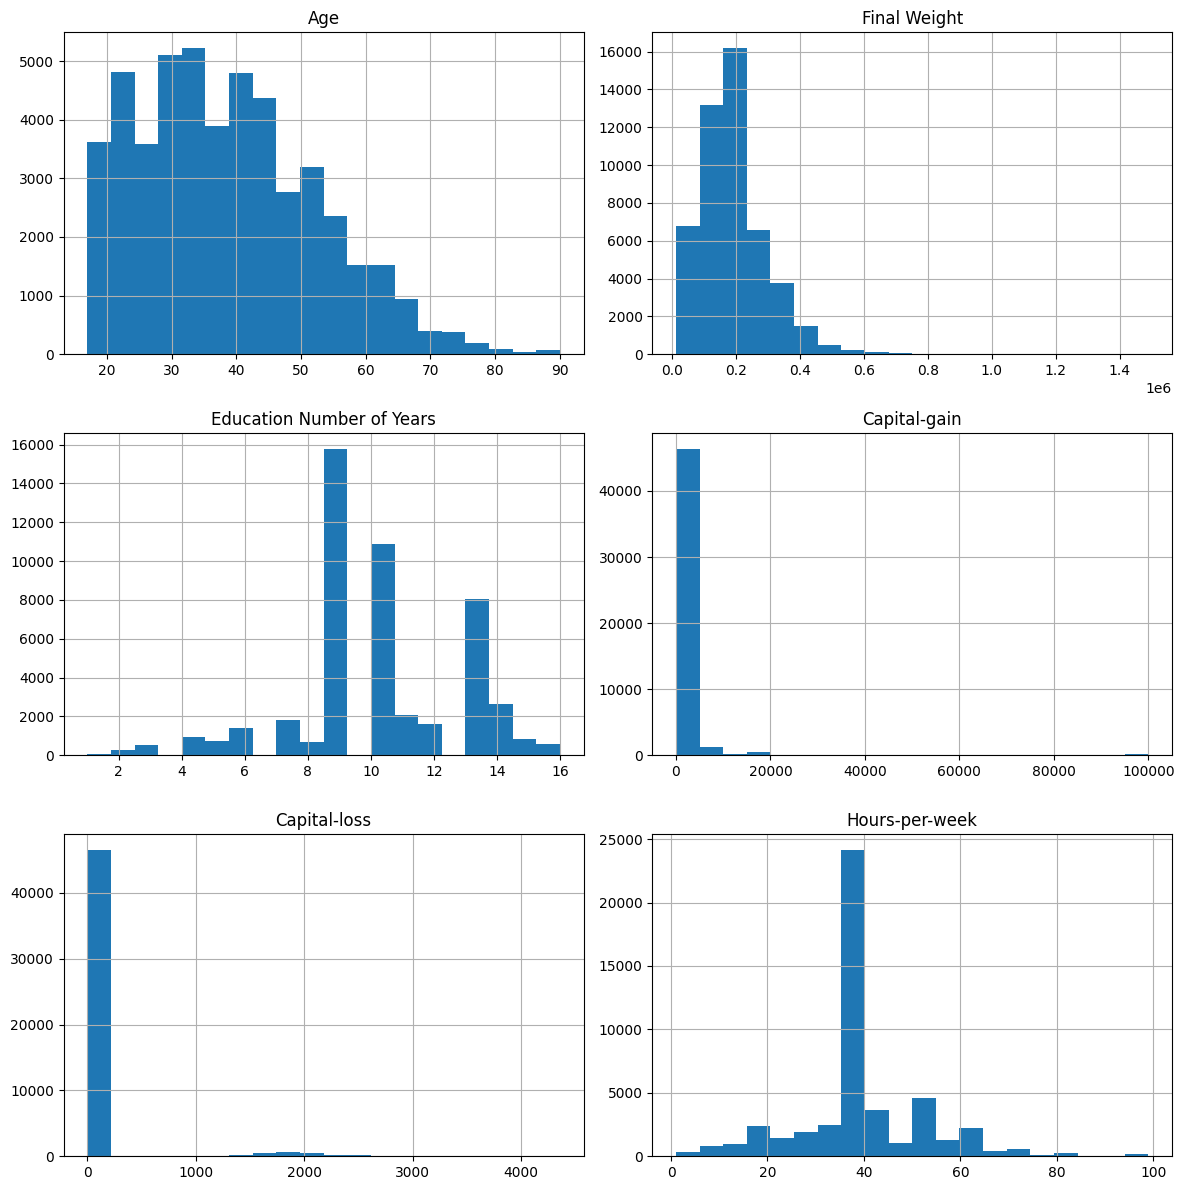

In [ ]:
numerical_data = dataset[
    [
        'Age',
        'Final Weight',
        'Education Number of Years',
        'Capital-gain',
        'Capital-loss',
        'Hours-per-week'
    ]
]
numerical_data.hist(figsize=(12, 12), bins=20)
plt.tight_layout()
plt.show()

In [ ]:
print(dataset['target'].value_counts())
print(dataset['target'].value_counts(normalize=True) * 100)

target
<=50K    37155
>50K     11687
Name: count, dtype: int64
target
<=50K    76.071823
>50K     23.928177
Name: proportion, dtype: float64


In [ ]:
dataset.describe().T

,count,mean,std,min,25%,50%,75%,max
Age,48842.0,38.643585,13.710510,17.0,28.0,37.0,48.0,90.0
Final Weight,48842.0,189664.134597,105604.025423,12285.0,117550.5,178144.5,237642.0,1490400.0
Education Number of Years,48842.0,10.078089,2.570973,1.0,9.0,10.0,12.0,16.0
Capital-gain,48842.0,1079.067626,7452.019058,0.0,0.0,0.0,0.0,99999.0
Capital-loss,48842.0,87.502314,403.004552,0.0,0.0,0.0,0.0,4356.0
Hours-per-week,48842.0,40.422382,12.391444,1.0,40.0,40.0,45.0,99.0


In [ ]:
print("Duplicate rows before removal:", dataset.duplicated().sum())
dataset = dataset.drop_duplicates().reset_index(drop=True)
print("Duplicate rows after removal:", dataset.duplicated().sum())

Duplicate rows before removal: 52
Duplicate rows after removal: 0


In [ ]:
for col in dataset.select_dtypes(include='object').columns:
    print("\n", col)
    print(dataset[col].value_counts())


 Workclass
Workclass
Private             33860
Self-emp-not-inc     3861
Local-gov            3136
?                    2795
State-gov            1981
Self-emp-inc         1694
Federal-gov          1432
Without-pay            21
Never-worked           10
Name: count, dtype: int64

 Education
Education
HS-grad         15770
Some-college    10863
Bachelors        8013
Masters          2656
Assoc-voc        2060
11th             1812
Assoc-acdm       1601
10th             1389
7th-8th           954
Prof-school       834
9th               756
12th              655
Doctorate         594
5th-6th           507
1st-4th           245
Preschool          81
Name: count, dtype: int64

 Marital-status
Marital-status
Married-civ-spouse       22366
Never-married            16082
Divorced                  6630
Separated                 1530
Widowed                   1518
Married-spouse-absent      627
Married-AF-spouse           37
Name: count, dtype: int64

 Occupation
Occupation
Prof-specialty     

In [ ]:
dataset.nunique()

,0
Age,74
Workclass,9
Final Weight,28523
Education,16
Education Number of Years,16
Marital-status,7
Occupation,15
Relationship,6
Race,5
Sex,2


In [ ]:
dataset.drop('Education', axis=1, inplace=True)

In [ ]:
dataset.head()

,Age,Workclass,Final Weight,Education Number of Years,Marital-status,Occupation,Relationship,Race,Sex,Capital-gain,Capital-loss,Hours-per-week,Native-country,target
0,39,State-gov,77516,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


In [ ]:
dataset['Sex'] = dataset['Sex'].map({'Male': 1,'Female': 0})

In [ ]:
dataset.head()

,Age,Workclass,Final Weight,Education Number of Years,Marital-status,Occupation,Relationship,Race,Sex,Capital-gain,Capital-loss,Hours-per-week,Native-country,target
0,39,State-gov,77516,13,Never-married,Adm-clerical,Not-in-family,White,1,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,13,Married-civ-spouse,Exec-managerial,Husband,White,1,0,0,13,United-States,<=50K
2,38,Private,215646,9,Divorced,Handlers-cleaners,Not-in-family,White,1,0,0,40,United-States,<=50K
3,53,Private,234721,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,1,0,0,40,United-States,<=50K
4,28,Private,338409,13,Married-civ-spouse,Prof-specialty,Wife,Black,0,0,0,40,Cuba,<=50K


In [ ]:
dataset.replace('?', np.nan, inplace=True)

In [ ]:
dataset['target'] = dataset['target'].map({'<=50K': 0,'>50K': 1})
dataset.head()

,Age,Workclass,Final Weight,Education Number of Years,Marital-status,Occupation,Relationship,Race,Sex,Capital-gain,Capital-loss,Hours-per-week,Native-country,target
0,39,State-gov,77516,13,Never-married,Adm-clerical,Not-in-family,White,1,2174,0,40,United-States,0
1,50,Self-emp-not-inc,83311,13,Married-civ-spouse,Exec-managerial,Husband,White,1,0,0,13,United-States,0
2,38,Private,215646,9,Divorced,Handlers-cleaners,Not-in-family,White,1,0,0,40,United-States,0
3,53,Private,234721,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,1,0,0,40,United-States,0
4,28,Private,338409,13,Married-civ-spouse,Prof-specialty,Wife,Black,0,0,0,40,Cuba,0


In [ ]:
dataset.drop('Native-country', axis=1, inplace=True)

In [ ]:
dataset.isnull().sum()

,0
Age,0
Workclass,2795
Final Weight,0
Education Number of Years,0
Marital-status,0
Occupation,2805
Relationship,0
Race,0
Sex,0
Capital-gain,0


In [ ]:
dataset[['Workclass', 'Occupation']] = (dataset[['Workclass', 'Occupation']].fillna('Missing'))

In [ ]:
df_encoded = pd.get_dummies(dataset,columns=['Workclass','Marital-status','Occupation','Relationship','Race'],dtype=int)
df_encoded.head()

,Age,Final Weight,Education Number of Years,Sex,Capital-gain,Capital-loss,Hours-per-week,target,Workclass_Federal-gov,Workclass_Local-gov,...,Relationship_Not-in-family,Relationship_Other-relative,Relationship_Own-child,Relationship_Unmarried,Relationship_Wife,Race_Amer-Indian-Eskimo,Race_Asian-Pac-Islander,Race_Black,Race_Other,Race_White
0,39,77516,13,1,2174,0,40,0,0,0,...,1,0,0,0,0,0,0,0,0,1
1,50,83311,13,1,0,0,13,0,0,0,...,0,0,0,0,0,0,0,0,0,1
2,38,215646,9,1,0,0,40,0,0,0,...,1,0,0,0,0,0,0,0,0,1
3,53,234721,7,1,0,0,40,0,0,0,...,0,0,0,0,0,0,0,1,0,0
4,28,338409,13,0,0,0,40,0,0,0,...,0,0,0,0,1,0,0,1,0,0


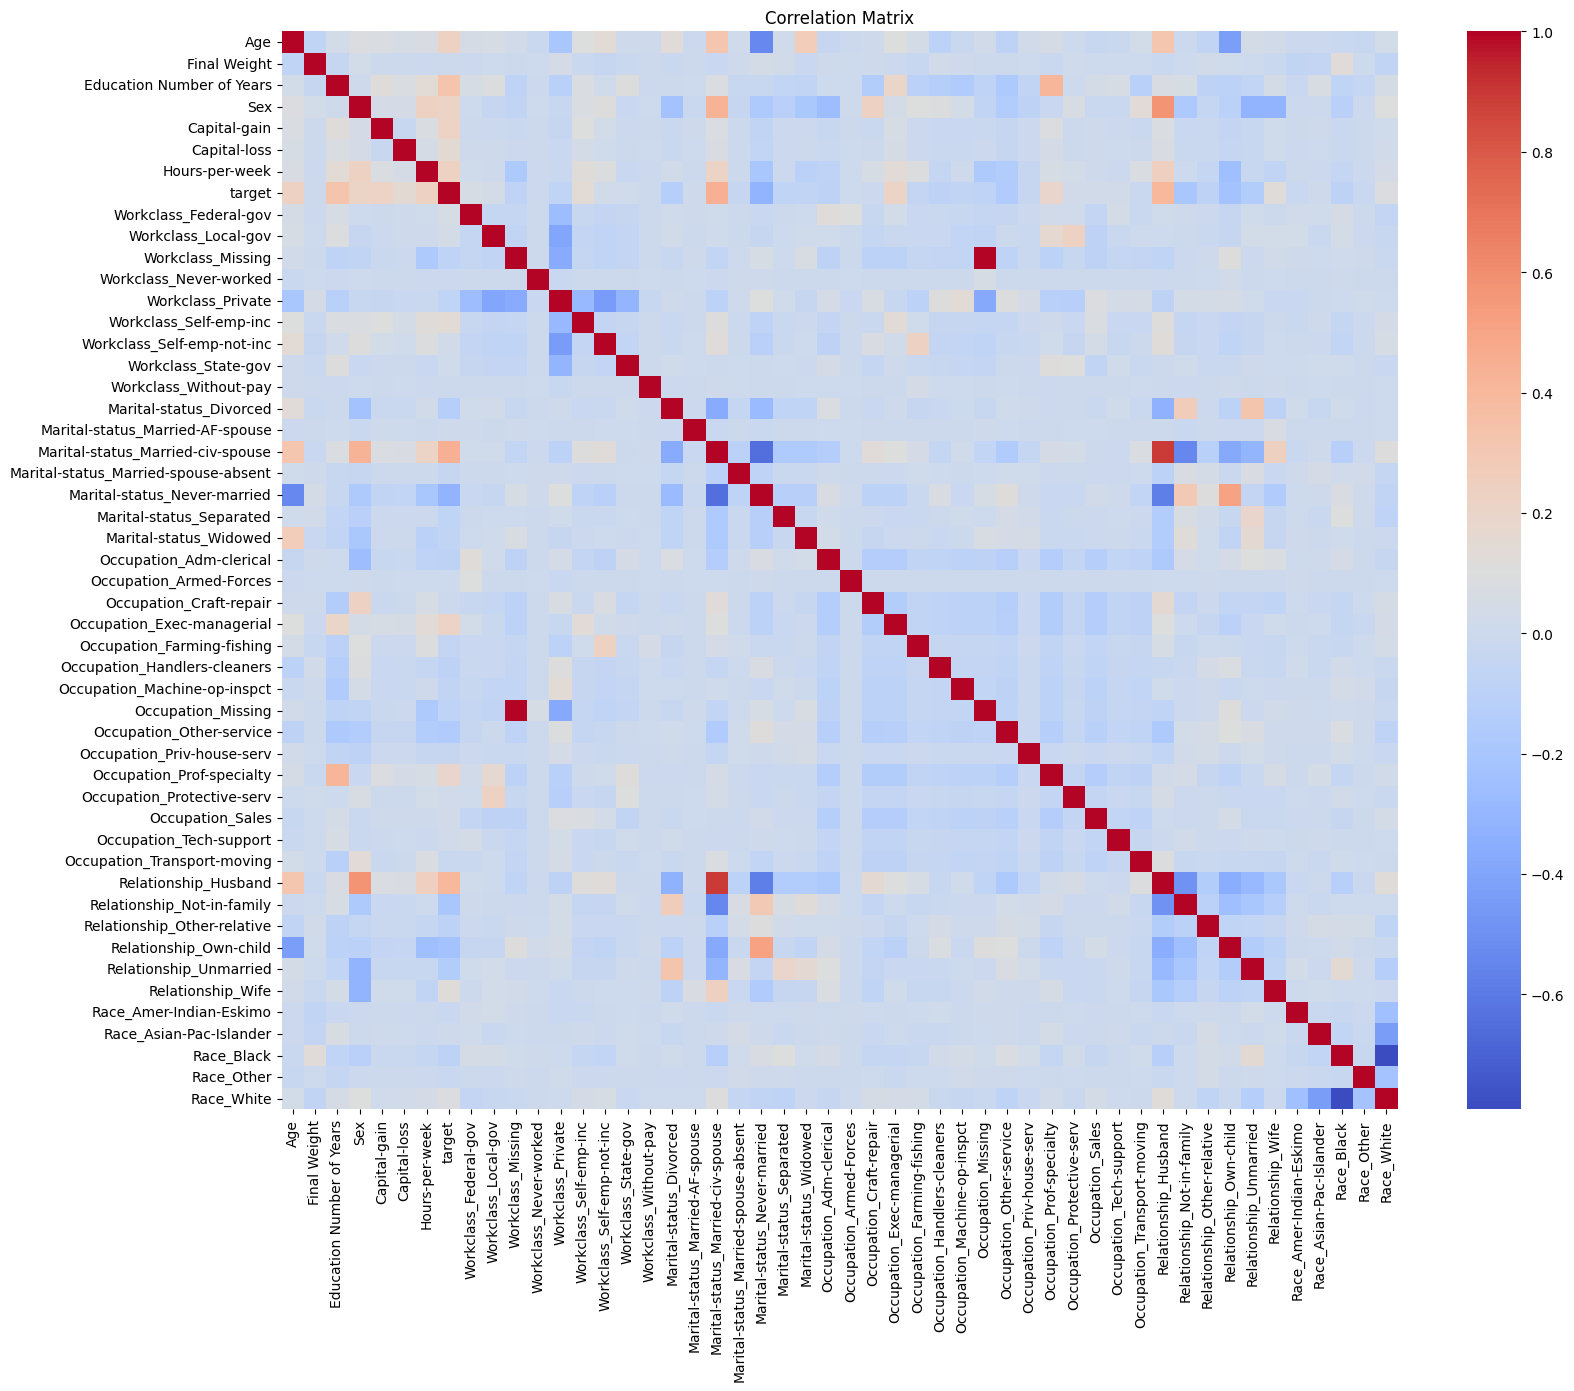

In [ ]:
df_corr = df_encoded.corr()
plt.figure(figsize=(18, 14))
sns.heatmap(df_corr, cmap='coolwarm')
plt.title('Correlation Matrix')
plt.show()


In [ ]:
target_corr = df_corr['target'].sort_values(ascending=False)
pd.set_option('display.max_rows', None)
print(target_corr)

target                                  1.000000
Marital-status_Married-civ-spouse       0.445663
Relationship_Husband                    0.403581
Education Number of Years               0.332802
Age                                     0.230144
Hours-per-week                          0.227664
Capital-gain                            0.223047
Sex                                     0.214639
Occupation_Exec-managerial              0.210818
Occupation_Prof-specialty               0.188799
Capital-loss                            0.147542
Workclass_Self-emp-inc                  0.139691
Relationship_Wife                       0.120459
Race_White                              0.083763
Workclass_Federal-gov                   0.062081
Workclass_Local-gov                     0.034508
Workclass_Self-emp-not-inc              0.027156
Occupation_Protective-serv              0.024931
Occupation_Sales                        0.023991
Occupation_Tech-support                 0.020979
Workclass_State-gov 

In [ ]:
numerical_cols = [
    'Age',
    'Final Weight',
    'Education Number of Years',
    'Capital-gain',
    'Capital-loss',
    'Hours-per-week'
]
df_encoded[numerical_cols].skew()

,0
Age,0.556582
Final Weight,1.439698
Education Number of Years,-0.314229
Capital-gain,11.888265
Capital-loss,4.567037
Hours-per-week,0.239652


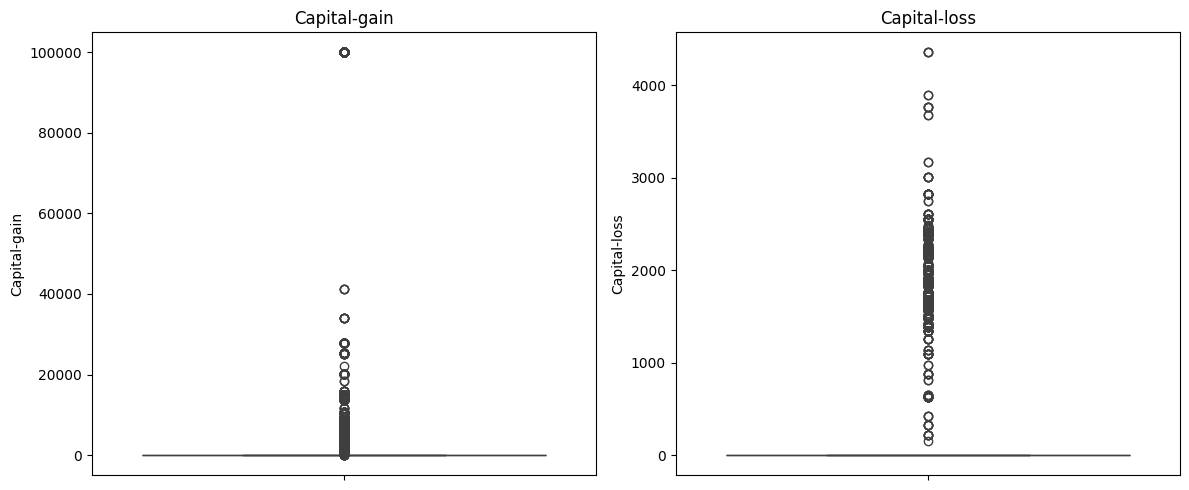

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.boxplot(y=df_encoded['Capital-gain'], ax=axes[0])
axes[0].set_title('Capital-gain')
sns.boxplot(y=df_encoded['Capital-loss'], ax=axes[1])
axes[1].set_title('Capital-loss')
plt.tight_layout()
plt.show()

In [ ]:
df_encoded.drop('Final Weight', axis=1, inplace=True)
df_encoded.head()

,Age,Education Number of Years,Sex,Capital-gain,Capital-loss,Hours-per-week,target,Workclass_Federal-gov,Workclass_Local-gov,Workclass_Missing,...,Relationship_Not-in-family,Relationship_Other-relative,Relationship_Own-child,Relationship_Unmarried,Relationship_Wife,Race_Amer-Indian-Eskimo,Race_Asian-Pac-Islander,Race_Black,Race_Other,Race_White
0,39,13,1,2174,0,40,0,0,0,0,...,1,0,0,0,0,0,0,0,0,1
1,50,13,1,0,0,13,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1
2,38,9,1,0,0,40,0,0,0,0,...,1,0,0,0,0,0,0,0,0,1
3,53,7,1,0,0,40,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0
4,28,13,0,0,0,40,0,0,0,0,...,0,0,0,0,1,0,0,1,0,0


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.cluster import KMeans
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    roc_curve,
    auc
)
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.regularizers import l2

X = df_encoded.drop('target', axis=1)
y = df_encoded['target']
skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)
supervised_models = [
    'Logistic Regression',
    'KNN',
    'Neural Network'
]
all_models = [
    'Logistic Regression',
    'KNN',
    'Neural Network',
    'K-Means (Unsupervised)'
]

results = {
    name: {
        'acc': [],
        'prec': [],
        'rec': [],
        'f1': [],
        'auc': []
    }
    for name in supervised_models
}
km_results = {
    'acc': [],
    'prec': [],
    'rec': [],
    'f1': [],
    'auc': []
}
fold_cms = {
    name: []
    for name in all_models
}
true_labels_all = []
lr_probs_all = []
knn_probs_all = []
nn_probs_all = []
km_probs_all = []

K-Fold, Training, Evaluation, & Visualization


In [ ]:
fold_no = 1

for train_index, val_index in skf.split(X, y):
    print(f"\nProcessing Fold {fold_no}...")

    X_train_fold, X_val_fold = X.iloc[train_index], X.iloc[val_index]
    y_train_fold, y_val_fold = y.iloc[train_index], y.iloc[val_index]

    numerical_cols = ['Age', 'Education Number of Years', 'Capital-gain','Capital-loss', 'Hours-per-week']

    preprocessor = ColumnTransformer(
        [('num', StandardScaler(), numerical_cols)],
        remainder='passthrough'
    )

    X_train_scaled_array = preprocessor.fit_transform(X_train_fold)
    X_val_scaled_array = preprocessor.transform(X_val_fold)

    scaled_cols = numerical_cols + [c for c in X_train_fold.columns if c not in numerical_cols]

    X_train_scaled = pd.DataFrame(X_train_scaled_array, columns=scaled_cols)
    X_val_scaled = pd.DataFrame(X_val_scaled_array, columns=scaled_cols)

    undersampler = RandomUnderSampler(random_state=27)
    X_train_res, y_train_res = undersampler.fit_resample(X_train_scaled, y_train_fold)

    print("before undersampling:")
    print(y_train_fold.value_counts())
    print("\nafter undersampling:")
    print(y_train_res.value_counts())

    lr = LogisticRegression(C=0.8, max_iter=1000, random_state=27)
    lr.fit(X_train_res, y_train_res)
    lr_prob = lr.predict_proba(X_val_scaled)[:, 1]
    lr_pred = lr.predict(X_val_scaled)

    results['Logistic Regression']['acc'].append(accuracy_score(y_val_fold, lr_pred))
    results['Logistic Regression']['prec'].append(precision_score(y_val_fold, lr_pred, zero_division=0))
    results['Logistic Regression']['rec'].append(recall_score(y_val_fold, lr_pred))
    results['Logistic Regression']['f1'].append(f1_score(y_val_fold, lr_pred))
    results['Logistic Regression']['auc'].append(roc_auc_score(y_val_fold, lr_prob))
    fold_cms['Logistic Regression'].append(confusion_matrix(y_val_fold, lr_pred))
    lr_probs_all.extend(lr_prob)

    knn = KNeighborsClassifier(n_neighbors=9)
    knn.fit(X_train_res, y_train_res)
    knn_prob = knn.predict_proba(X_val_scaled)[:, 1]
    knn_pred = knn.predict(X_val_scaled)

    results['KNN']['acc'].append(accuracy_score(y_val_fold, knn_pred))
    results['KNN']['prec'].append(precision_score(y_val_fold, knn_pred, zero_division=0))
    results['KNN']['rec'].append(recall_score(y_val_fold, knn_pred))
    results['KNN']['f1'].append(f1_score(y_val_fold, knn_pred))
    results['KNN']['auc'].append(roc_auc_score(y_val_fold, knn_prob))
    fold_cms['KNN'].append(confusion_matrix(y_val_fold, knn_pred))
    knn_probs_all.extend(knn_prob)

    tf.random.set_seed(27)
    X_nn_train, X_nn_val, y_nn_train, y_nn_val = train_test_split(
        X_train_res, y_train_res,
        test_size=0.2, stratify=y_train_res, random_state=27
    )

    nn = Sequential([
        Input(shape=(X_nn_train.shape[1],)),
        Dense(24, activation='relu', kernel_regularizer=l2(0.005)),
        Dropout(0.15),
        Dense(12, activation='relu', kernel_regularizer=l2(0.005)),
        Dropout(0.15),
        Dense(1, activation='sigmoid')
    ])

    nn.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.0008),
        loss='binary_crossentropy',
        metrics=['accuracy']
    )

    early_stop = EarlyStopping(
        monitor='val_loss', patience=8, restore_best_weights=True
    )

    nn.fit(
        X_nn_train, y_nn_train,
        epochs=100, batch_size=32,
        validation_data=(X_nn_val, y_nn_val),
        callbacks=[early_stop], verbose=0
    )

    nn_prob = nn.predict(X_val_scaled, verbose=0).flatten()
    nn_pred = (nn_prob >= 0.5).astype(int)

    results['Neural Network']['acc'].append(accuracy_score(y_val_fold, nn_pred))
    results['Neural Network']['prec'].append(precision_score(y_val_fold, nn_pred, zero_division=0))
    results['Neural Network']['rec'].append(recall_score(y_val_fold, nn_pred))
    results['Neural Network']['f1'].append(f1_score(y_val_fold, nn_pred))
    results['Neural Network']['auc'].append(roc_auc_score(y_val_fold, nn_prob))
    fold_cms['Neural Network'].append(confusion_matrix(y_val_fold, nn_pred))
    nn_probs_all.extend(nn_prob)

    kmeans = KMeans(n_clusters=2, random_state=27, n_init=15)
    kmeans.fit(X_train_scaled)

    train_clusters = kmeans.labels_
    y_train_array = y_train_fold.to_numpy()

    cluster_0_mean = y_train_array[train_clusters == 0].mean()
    cluster_1_mean = y_train_array[train_clusters == 1].mean()

    positive_cluster = 0 if cluster_0_mean > cluster_1_mean else 1

    val_clusters = kmeans.predict(X_val_scaled)
    km_pred = (val_clusters == positive_cluster).astype(int)
    km_prob = km_pred.astype(float)

    km_results['acc'].append(accuracy_score(y_val_fold, km_pred))
    km_results['prec'].append(precision_score(y_val_fold, km_pred, zero_division=0))
    km_results['rec'].append(recall_score(y_val_fold, km_pred))
    km_results['f1'].append(f1_score(y_val_fold, km_pred))
    km_results['auc'].append(roc_auc_score(y_val_fold, km_prob))
    fold_cms['K-Means (Unsupervised)'].append(confusion_matrix(y_val_fold, km_pred))

    km_probs_all.extend(km_prob)
    true_labels_all.extend(y_val_fold)

    fold_no += 1


Processing Fold 1...
before undersampling:
target
0    29687
1     9345
Name: count, dtype: int64

after undersampling:
target
0    9345
1    9345
Name: count, dtype: int64

Processing Fold 2...
before undersampling:
target
0    29687
1     9345
Name: count, dtype: int64

after undersampling:
target
0    9345
1    9345
Name: count, dtype: int64

Processing Fold 3...
before undersampling:
target
0    29687
1     9345
Name: count, dtype: int64

after undersampling:
target
0    9345
1    9345
Name: count, dtype: int64

Processing Fold 4...
before undersampling:
target
0    29687
1     9345
Name: count, dtype: int64

after undersampling:
target
0    9345
1    9345
Name: count, dtype: int64

Processing Fold 5...
before undersampling:
target
0    29688
1     9344
Name: count, dtype: int64

after undersampling:
target
0    9344
1    9344
Name: count, dtype: int64


In [ ]:
final_metrics = {}
for name in supervised_models:
    final_metrics[name] = {
        'Accuracy': np.mean(results[name]['acc']),
        'Precision': np.mean(results[name]['prec']),
        'Recall': np.mean(results[name]['rec']),
        'F1 Score': np.mean(results[name]['f1']),
        'AUC Score': np.mean(results[name]['auc'])
    }
comparison_df = pd.DataFrame(final_metrics).T
print("Supervised Model Comparison (Averaged across 5 Folds)")
display(comparison_df.round(4))
km_final = pd.DataFrame({
    'Accuracy': [np.mean(km_results['acc'])],
    'Precision': [np.mean(km_results['prec'])],
    'Recall': [np.mean(km_results['rec'])],
    'F1 Score': [np.mean(km_results['f1'])],
    'AUC Score': [np.mean(km_results['auc'])]
}, index=['K-Means (Unsupervised)'])
print("K-Means External Evaluation (Averaged across 5 Folds)")
display(km_final.round(4))

Supervised Model Comparison (Averaged across 5 Folds)


,Accuracy,Precision,Recall,F1 Score,AUC Score
Logistic Regression,0.8092,0.5683,0.8456,0.6797,0.9059
KNN,0.8003,0.5558,0.8276,0.6650,0.8889
Neural Network,0.8113,0.5707,0.8554,0.6846,0.9109


K-Means External Evaluation (Averaged across 5 Folds)


,Accuracy,Precision,Recall,F1 Score,AUC Score
K-Means (Unsupervised),0.7615,0.5101,0.0978,0.164,0.5341


In [ ]:
true_labels_all = np.array(true_labels_all)
lr_probs_all = np.array(lr_probs_all)
knn_probs_all = np.array(knn_probs_all)
nn_probs_all = np.array(nn_probs_all)
km_probs_all = np.array(km_probs_all)

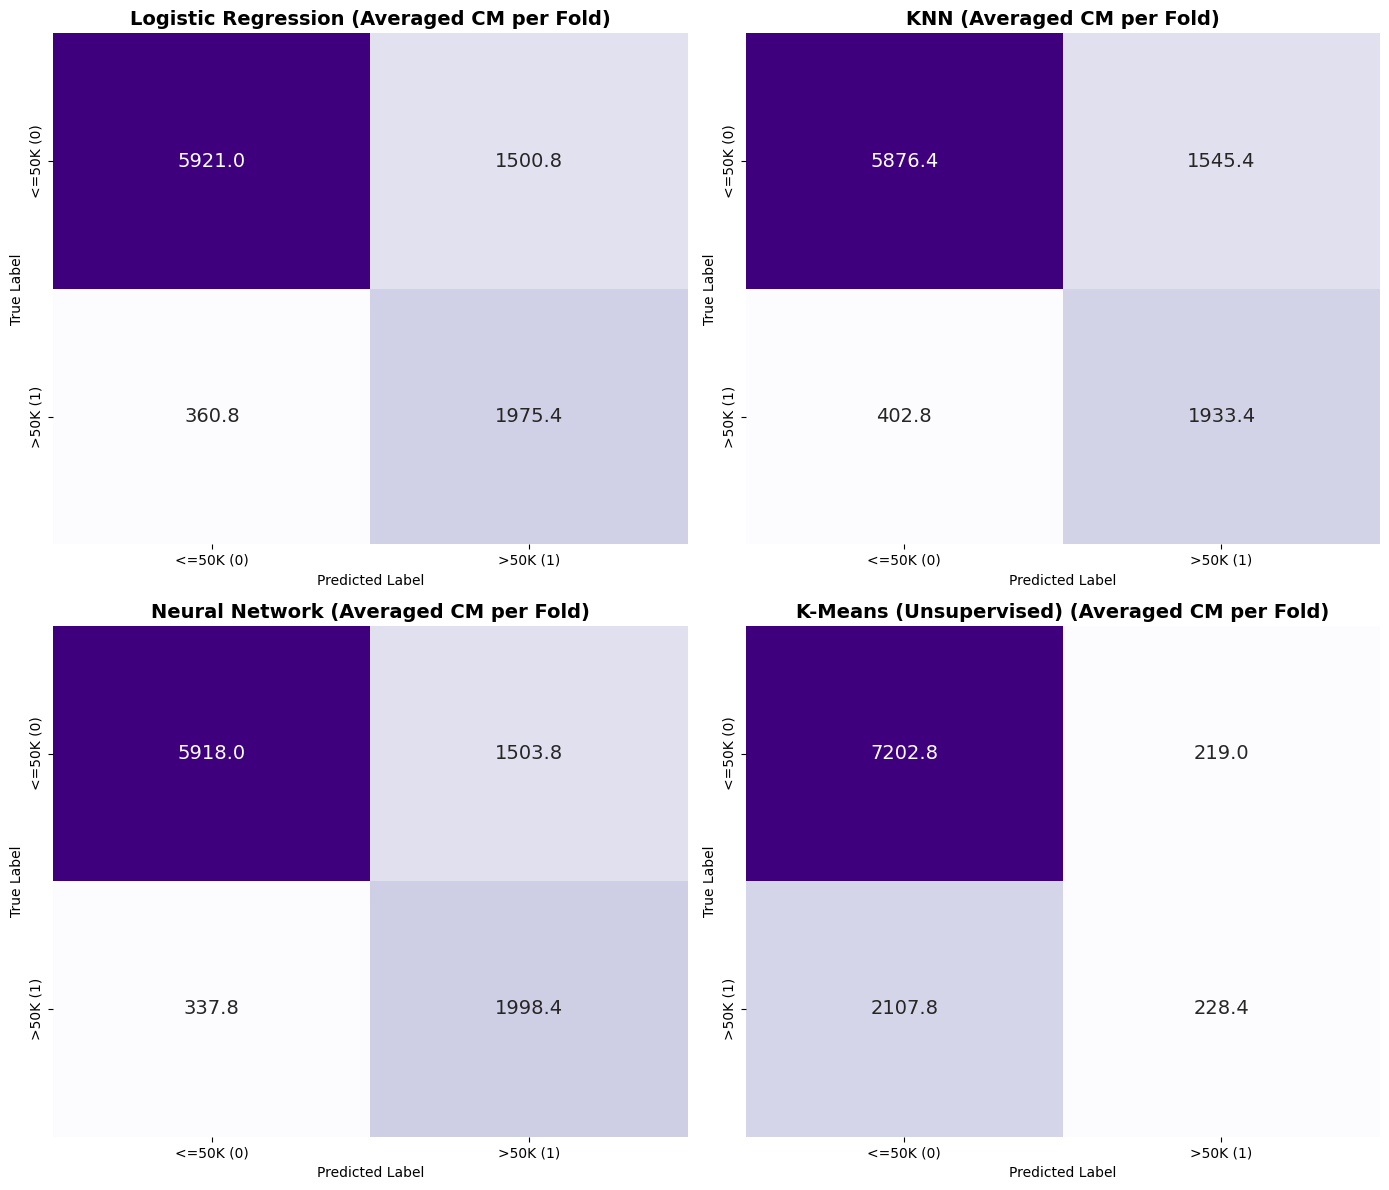

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(14, 12))
axes = axes.flatten()

for i, name in enumerate(all_models):
    avg_cm = np.mean(fold_cms[name], axis=0)
    sns.heatmap(avg_cm, annot=True, fmt='.1f', cmap='Purples', ax=axes[i], cbar=False, annot_kws={"size":14})
    axes[i].set_title(f'{name} (Averaged CM per Fold)', fontsize=14, fontweight='bold')
    axes[i].set(xlabel='Predicted Label', ylabel='True Label')
    axes[i].set_xticklabels(['<=50K (0)', '>50K (1)'])
    axes[i].set_yticklabels(['<=50K (0)', '>50K (1)'])

plt.tight_layout()
plt.show()

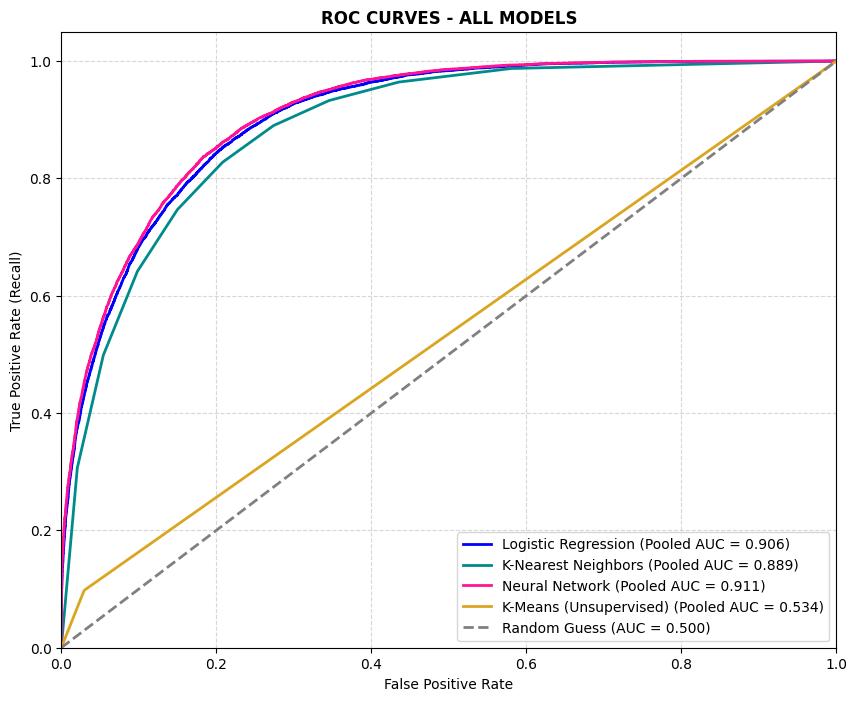

In [ ]:
plt.figure(figsize=(10, 8))
models_probs = [
    ('Logistic Regression', lr_probs_all, 'blue'),
    ('K-Nearest Neighbors', knn_probs_all, 'darkcyan'),
    ('Neural Network', nn_probs_all, 'deeppink'),
    ('K-Means (Unsupervised)', km_probs_all, 'goldenrod')
]
for name, y_prob, color in models_probs:
    fpr, tpr, _ = roc_curve(true_labels_all, y_prob)
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, color=color, lw=2, label=f'{name} (Pooled AUC = {roc_auc:.3f})')

plt.plot([0,1], [0,1], color='gray', lw=2, linestyle='--', label='Random Guess (AUC = 0.500)')
plt.xlim([0,1]); plt.ylim([0,1.05])
plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate (Recall)')
plt.title('ROC CURVES - ALL MODELS', fontweight='bold')
plt.legend(loc='lower right'); plt.grid(True, linestyle='--', alpha=0.5)
plt.show()